# Model-selection tables: distinctness, stability, fit, MVSA vs NMF

Collects, for all five elections and both extractors, the numbers behind the
"choice of $p$" and "MVSA vs NMF" parts of the paper outline
(`voting-unmixing-ph-paper/outline-organized.tex`):

| section | outline table | source |
|---|---|---|
| 0. provenance | (check) | sweep `meta.json` vs `configs/` |
| 1. distinctness vs $p$ | `tab:jac` | `data/distinctness/` (`bake_distinctness.py`) |
| 2. order and seed sensitivity | `tab:stab` | `data/order_sensitivity/` (`bake_order_sensitivity.py`) |
| 3. fit vs $p$ | `tab:rmse` | sweep `meta.json` (`run_sweep.py`) |
| 4. MVSA vs NMF agreement | `tab:agree` | sweep `loadings_mean.csv` |

Nothing here re-runs the unmixing; it reads the baked outputs. Re-run the
scripts above first if the pipeline has changed.

In [1]:
import json
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import REPO_ROOT, load_config, method_path
from src.data.loading import load_sweep
from src.unmixing.matching import match_to_reference

sns.set_style("whitegrid")

YEARS = ["2013", "2016", "2019", "2022", "2025"]
METHODS = {"mvsa": "MVSA", "nmf": "NMF"}
CONFIGS = {y: load_config(REPO_ROOT / "configs" / f"config_{y}.ini") for y in YEARS}
P_MAIN = 4  # the p used in the paper
METRIC = "jac12"  # top-12 Jaccard; other keys: cos12, cos, spearman, wtau, rbo
DATA = REPO_ROOT / "data"


def load_bake(kind, year, method):
    # data/<kind>/<year>.json for MVSA, data/<kind>/nmf/<year>.json for NMF
    folder = DATA / kind if method == "mvsa" else DATA / kind / method
    with open(folder / f"{year}.json") as f:
        return json.load(f)


SWEEPS = {(y, m): load_sweep(CONFIGS[y], method=m) for y in YEARS for m in METHODS}
{k: sorted(v) for k, v in SWEEPS.items()}

{('2013', 'mvsa'): [2, 3, 4, 5, 6, 7],
 ('2013', 'nmf'): [2, 3, 4, 5, 6, 7],
 ('2016', 'mvsa'): [2, 3, 4, 5, 6, 7],
 ('2016', 'nmf'): [2, 3, 4, 5, 6, 7],
 ('2019', 'mvsa'): [2, 3, 4, 5, 6, 7],
 ('2019', 'nmf'): [2, 3, 4, 5, 6, 7],
 ('2022', 'mvsa'): [2, 3, 4, 5, 6, 7],
 ('2022', 'nmf'): [2, 3, 4, 5, 6, 7],
 ('2025', 'mvsa'): [2, 3, 4, 5, 6, 7],
 ('2025', 'nmf'): [2, 3, 4, 5, 6, 7]}

## 0. Provenance: what each sweep was run on

The sweeps record the preprocessing they used. If a config changed after a
sweep was run (e.g. a region added to `excluded_regions`), the MVSA and NMF
sweeps of the same year may not cover the same precincts, and the baked
numbers no longer match the current config.

In [2]:
rows = []
for (y, m), sw in SWEEPS.items():
    meta = sw[P_MAIN]["meta"]
    pre = meta["preprocessing"]
    cfg = CONFIGS[y]["preprocessing"]
    cfg_excl = [r.strip() for r in cfg["excluded_regions"].split(",") if r.strip()]
    rows.append(
        {
            "year": y,
            "method": METHODS[m],
            "excluded (sweep)": ",".join(pre["excluded_regions"]),
            "excluded (config now)": ",".join(cfg_excl),
            "min 25th pct": pre["min_candidate_25th_percentile"],
            "min votes": pre["min_precinct_votes"],
            "normalization": pre["normalization"],
            "candidates": len(meta["candidate_labels"]),
            "precincts before filter": pre.get("n_precincts_before"),
            "trials": meta["n_trials"],
            "reference trial": meta["reference_trial"],
        }
    )
prov = pd.DataFrame(rows).set_index(["year", "method"]).sort_index()
prov["sweep = config"] = prov["excluded (sweep)"] == prov["excluded (config now)"]
prov

excluded (sweep) excluded (config now)  min 25th pct  min votes  \
year method                                                                   
2013 MVSA             OV,LAV                OV,LAV          10.0       10.0   
     NMF              OV,LAV                OV,LAV          10.0       10.0   
2016 MVSA             OV,LAV                OV,LAV          10.0       10.0   
     NMF              OV,LAV                OV,LAV          10.0       10.0   
2019 MVSA             OV,LAV                OV,LAV          10.0       10.0   
     NMF              OV,LAV                OV,LAV          10.0       10.0   
2022 MVSA         OV,LAV,OAV            OV,LAV,OAV          10.0       10.0   
     NMF          OV,LAV,OAV            OV,LAV,OAV          10.0       10.0   
2025 MVSA         OV,LAV,OAV            OV,LAV,OAV          10.0       10.0   
     NMF          OV,LAV,OAV            OV,LAV,OAV          10.0       10.0   

             normalization  candidates  precincts before filter  trials  \
year method                                                               
2013 MVSA          row_max          19                    77830      50   
     NMF           row_max          19                    77830      50   
2016 MVSA          row_max          32                    22986      50   
     NMF           row_max          32                    22986      50   
2019 MVSA    valid_ballots          32                    85116      50   
     NMF     valid_ballots          32                    85116      50   
2022 MVSA    valid_ballots          34                   105033      50   
     NMF     valid_ballots          34                   105033      50   
2025 MVSA    valid_ballots          42                    92488      50   
     NMF     valid_ballots          42                    92488      50   

             reference trial  sweep = config  
year method                                   
2013 MVSA                  5            True  
     NMF                   6            True  
2016 MVSA                  2            True  
     NMF                   2            True  
2019 MVSA                 40            True  
     NMF                  24            True  
2022 MVSA                  1            True  
     NMF                  48            True  
2025 MVSA                 35            True  
     NMF                  16            True

In [3]:
# Do the MVSA and NMF sweeps of each year share the same preprocessing?
cols = ["excluded (sweep)", "min 25th pct", "min votes", "normalization", "candidates"]
same = {
    y: all(prov.loc[(y, "MVSA"), c] == prov.loc[(y, "NMF"), c] for c in cols)
    for y in YEARS
}
pd.Series(same, name="MVSA and NMF sweeps share preprocessing")

2013    True
2016    True
2019    True
2022    True
2025    True
Name: MVSA and NMF sweeps share preprocessing, dtype: bool

## 1. Distinctness vs $p$ (outline `tab:jac`)

Minimum pairwise distance between the archetypes of one run (config seed),
on the 0 = identical ... 1 = maximally distinct scale of notebook 08. The
paper's primary metric is top-12 Jaccard (`jac12`).

Note: this is a **single run** per $p$, not a trial distribution.

In [4]:
def distinct_table(metric=METRIC, stat="min", ps=range(2, 8)):
    out = {}
    for m, label in METHODS.items():
        for y in YEARS:
            d = load_bake("distinctness", y, m)
            out[(label, y)] = {
                p: d["distinct"][str(p)][metric][stat] for p in ps if str(p) in d["distinct"]
            }
    df = pd.DataFrame(out).T
    df.index.names = ["method", "year"]
    df.columns.name = "p"
    return df


tab_jac = distinct_table()
tab_jac.round(2)

p               2     3     4     5     6     7
method year                                    
MVSA   2013  0.59  0.59  0.40  0.29  0.40  0.15
       2016  0.59  0.67  0.67  0.67  0.59  0.40
       2019  0.80  0.86  0.59  0.50  0.40  0.50
       2022  0.74  0.80  0.74  0.59  0.50  0.59
       2025  1.00  0.74  0.86  0.50  0.50  0.40
NMF    2013  0.59  0.40  0.40  0.29  0.29  0.15
       2016  0.59  0.59  0.50  0.40  0.40  0.40
       2019  0.67  0.59  0.50  0.40  0.40  0.29
       2022  0.74  0.59  0.40  0.29  0.50  0.29
       2025  0.96  0.74  0.59  0.59  0.50  0.50

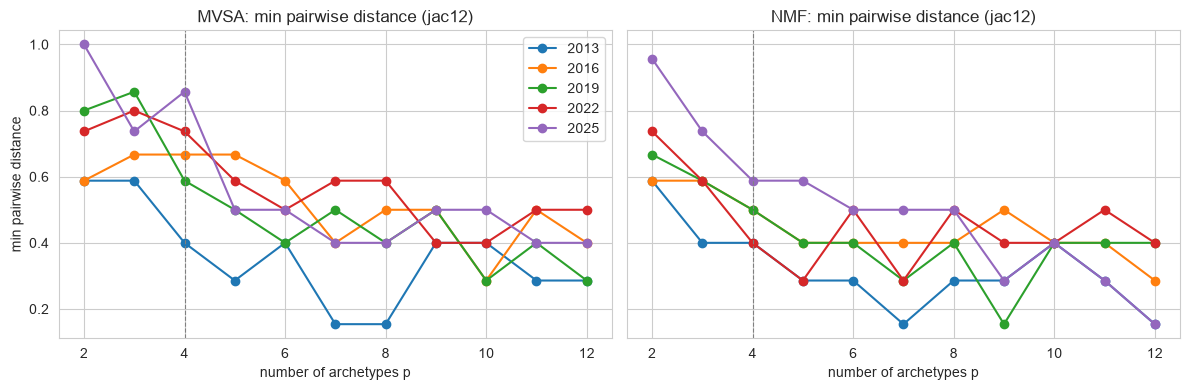

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (m, label) in zip(axes, METHODS.items()):
    for y in YEARS:
        d = load_bake("distinctness", y, m)
        ps = d["ps"]
        ax.plot(ps, [d["distinct"][str(p)][METRIC]["min"] for p in ps], marker="o", label=y)
    ax.axvline(P_MAIN, color="grey", ls="--", lw=0.8)
    ax.set(title=f"{label}: min pairwise distance ({METRIC})", xlabel="number of archetypes p")
axes[0].set_ylabel("min pairwise distance")
axes[0].legend()
plt.tight_layout()

In [6]:
# Where does distinctness *rise* from p to p+1 (non-monotone steps)?
rises = [
    (lab, y, p, tab_jac.loc[(lab, y), p], tab_jac.loc[(lab, y), p + 1])
    for (lab, y) in tab_jac.index
    for p in range(2, 7)
    if tab_jac.loc[(lab, y), p + 1] > tab_jac.loc[(lab, y), p]
]
pd.DataFrame(rises, columns=["method", "year", "p", "d(p)", "d(p+1)"]).round(3)

,method,year,p,d(p),d(p+1)
0,MVSA,2013,5,0.286,0.400
1,MVSA,2016,2,0.588,0.667
2,MVSA,2019,2,0.800,0.857
3,MVSA,2019,6,0.400,0.500
4,MVSA,2022,2,0.737,0.800
5,MVSA,2022,6,0.500,0.588
6,MVSA,2025,3,0.737,0.857
7,NMF,2022,5,0.286,0.500


In [7]:
# Floor summary: lowest distance at p <= 4 vs highest at p >= 5, per year
floor = pd.DataFrame(
    {
        "min d, p=2..4": tab_jac[[2, 3, 4]].min(axis=1),
        "max d, p=5..7": tab_jac[[5, 6, 7]].max(axis=1),
    }
)
floor["drops after p=4"] = floor["max d, p=5..7"] < floor["min d, p=2..4"]
floor.round(3)

min d, p=2..4  max d, p=5..7  drops after p=4
method year                                               
MVSA   2013          0.400          0.400            False
       2016          0.588          0.667            False
       2019          0.588          0.500             True
       2022          0.737          0.588             True
       2025          0.737          0.500             True
NMF    2013          0.400          0.286             True
       2016          0.500          0.400             True
       2019          0.500          0.400             True
       2022          0.400          0.500            False
       2025          0.588          0.588            False

### Which metric behaves consistently?

For each metric and extractor, count the years (out of 5) in which
(a) the distance at $p=5$ is below every distance at $p=2..4$, and
(b) the distance never rises from $p$ to $p+1$ over $p=2..7$.
This tests the claim that top-12 Jaccard is the metric whose behaviour with
$p$ is consistent across years and between MVSA and NMF.

In [8]:
rows = []
for metric in ["cos12", "cos", "spearman", "wtau", "rbo", "jac12"]:
    t = distinct_table(metric=metric)
    for lab in METHODS.values():
        sub = t.xs(lab, level="method")
        drop = sub[5] < sub[[2, 3, 4]].min(axis=1)
        mono = (sub.diff(axis=1).iloc[:, 1:] <= 1e-12).all(axis=1)
        rows.append(
            {
                "metric": metric,
                "method": lab,
                "d(5) < min d(2..4)": int(drop.sum()),
                "monotone over 2..7": int(mono.sum()),
            }
        )
pd.DataFrame(rows).pivot(index="metric", columns="method")

d(5) < min d(2..4)     monotone over 2..7    
method                 MVSA NMF               MVSA NMF
metric                                                
cos                       2   0                  0   0
cos12                     2   1                  0   0
jac12                     4   4                  0   4
rbo                       3   4                  1   0
spearman                  3   3                  0   0
wtau                      4   3                  1   1

## 2. Sensitivity to precinct order and seed (outline `tab:stab`)

Matched similarity of each trial's archetypes to the reference run, pooled
over trials $\times$ archetypes (notebook 09 design). Arm B: shuffled precinct
order, fixed seed. Arm C: canonical order, varying seed.

In [9]:
def stability_table(metric=METRIC):
    rows = []
    for m, label in METHODS.items():
        for y in YEARS:
            d = load_bake("order_sensitivity", y, m)
            for i, p in enumerate(d["ps"]):
                for arm in ("B", "C"):
                    s = np.asarray(d["sims"][arm][metric][i], dtype=float).ravel()
                    rows.append(
                        {"method": label, "year": y, "p": p, "arm": arm,
                         "mean": s.mean(), "min": s.min(), "n": s.size}
                    )
    return pd.DataFrame(rows)


stab = stability_table()
cell = stab["mean"].map("{:.2f}".format) + " [" + stab["min"].map("{:.2f}".format) + "]"
stab.assign(cell=cell).pivot_table(
    index=["method", "year"], columns=["p", "arm"], values="cell", aggfunc="first"
)

p                      2                         3                         4  \
arm                    B            C            B            C            B   
method year                                                                    
MVSA   2013  1.00 [1.00]  1.00 [1.00]  1.00 [1.00]  0.97 [0.71]  0.90 [0.71]   
       2016  1.00 [1.00]  1.00 [1.00]  1.00 [1.00]  0.97 [0.85]  0.92 [0.26]   
       2019  1.00 [1.00]  1.00 [1.00]  1.00 [1.00]  0.94 [0.33]  0.91 [0.50]   
       2022  1.00 [1.00]  1.00 [1.00]  1.00 [1.00]  0.95 [0.71]  0.95 [0.60]   
       2025  1.00 [1.00]  1.00 [1.00]  1.00 [1.00]  0.98 [0.85]  0.99 [0.85]   
NMF    2013  1.00 [1.00]  0.94 [0.60]  1.00 [1.00]  0.85 [0.60]  1.00 [0.85]   
       2016  0.99 [0.85]  0.73 [0.50]  0.99 [0.85]  0.73 [0.41]  0.69 [0.41]   
       2019  1.00 [1.00]  0.99 [0.85]  1.00 [1.00]  0.83 [0.41]  1.00 [1.00]   
       2022  1.00 [1.00]  0.96 [0.85]  0.99 [0.85]  0.89 [0.41]  0.96 [0.71]   
       2025  1.00 [1.00]  1.00 [1.00]  1.00 [1.00]  0.96 [0.71]  1.00 [1.00]   

p                                   5                         6               
arm                    C            B            C            B            C  
method year                                                                   
MVSA   2013  0.78 [0.33]  0.97 [0.71]  0.85 [0.41]  0.74 [0.26]  0.73 [0.26]  
       2016  0.59 [0.33]  0.90 [0.20]  0.70 [0.26]  0.65 [0.26]  0.61 [0.14]  
       2019  0.85 [0.26]  0.82 [0.50]  0.79 [0.20]  0.72 [0.26]  0.79 [0.26]  
       2022  0.97 [0.60]  0.79 [0.41]  0.82 [0.20]  0.70 [0.26]  0.64 [0.14]  
       2025  0.96 [0.33]  0.84 [0.26]  0.80 [0.09]  0.76 [0.26]  0.70 [0.04]  
NMF    2013  0.77 [0.41]  0.97 [0.85]  0.72 [0.33]  0.97 [0.85]  0.75 [0.41]  
       2016  0.74 [0.33]  0.82 [0.41]  0.70 [0.26]  0.98 [0.85]  0.65 [0.14]  
       2019  0.92 [0.71]  0.80 [0.41]  0.82 [0.26]  0.94 [0.60]  0.74 [0.09]  
       2022  0.76 [0.33]  0.96 [0.60]  0.74 [0.20]  0.99 [0.85]  0.73 [0.14]  
       2025  0.87 [0.33]  1.00 [0.85]  0.78 [0.26]  1.00 [1.00]  0.75 [0.00]

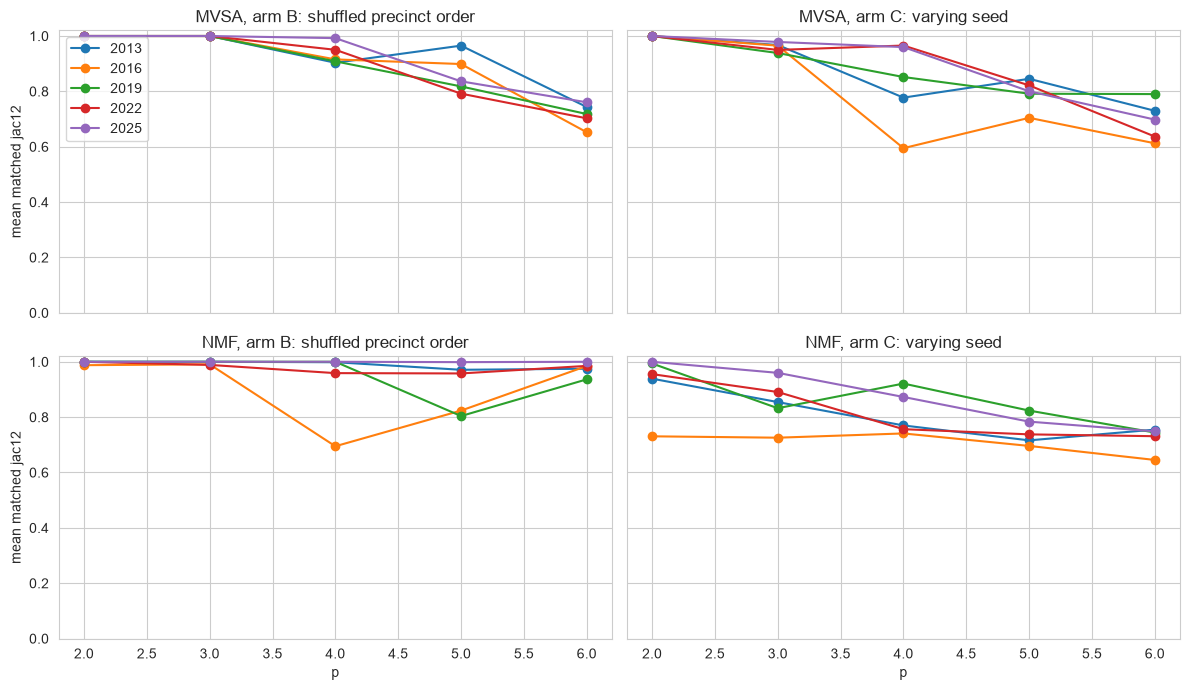

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for i, label in enumerate(METHODS.values()):
    for j, (arm, name) in enumerate([("B", "shuffled precinct order"), ("C", "varying seed")]):
        ax = axes[i, j]
        sub = stab[(stab["method"] == label) & (stab["arm"] == arm)]
        for y, g in sub.groupby("year"):
            ax.plot(g["p"], g["mean"], marker="o", label=y)
        ax.set(title=f"{label}, arm {arm}: {name}", ylim=(0, 1.02))
        if i == 1:
            ax.set_xlabel("p")
        if j == 0:
            ax.set_ylabel(f"mean matched {METRIC}")
axes[0, 0].legend()
plt.tight_layout()

In [11]:
# Claim checks: NMF less order-sensitive (arm B), more seed-sensitive (arm C)?
means = stab.pivot_table(index=["arm", "year", "p"], columns="method", values="mean")
checks = pd.DataFrame(
    {
        "NMF less order-sensitive (B)": (means.loc["B", "NMF"] > means.loc["B", "MVSA"]),
        "NMF more seed-sensitive (C)": (means.loc["C", "NMF"] < means.loc["C", "MVSA"]),
        "B: MVSA": means.loc["B", "MVSA"],
        "B: NMF": means.loc["B", "NMF"],
        "C: MVSA": means.loc["C", "MVSA"],
        "C: NMF": means.loc["C", "NMF"],
    }
)
checks.round(2)

NMF less order-sensitive (B)  NMF more seed-sensitive (C)  B: MVSA  \
year p                                                                       
2013 2                         False                         True     1.00   
     3                         False                         True     1.00   
     4                          True                         True     0.90   
     5                          True                         True     0.97   
     6                          True                        False     0.74   
2016 2                         False                         True     1.00   
     3                         False                         True     1.00   
     4                         False                        False     0.92   
     5                         False                         True     0.90   
     6                          True                        False     0.65   
2019 2                         False                         True     1.00   
     3                         False                         True     1.00   
     4                          True                        False     0.91   
     5                         False                        False     0.82   
     6                          True                         True     0.72   
2022 2                         False                         True     1.00   
     3                         False                         True     1.00   
     4                          True                         True     0.95   
     5                          True                         True     0.79   
     6                          True                        False     0.70   
2025 2                         False                        False     1.00   
     3                         False                         True     1.00   
     4                          True                         True     0.99   
     5                          True                         True     0.84   
     6                          True                        False     0.76   

        B: NMF  C: MVSA  C: NMF  
year p                           
2013 2    1.00     1.00    0.94  
     3    1.00     0.97    0.85  
     4    1.00     0.78    0.77  
     5    0.97     0.85    0.72  
     6    0.97     0.73    0.75  
2016 2    0.99     1.00    0.73  
     3    0.99     0.97    0.73  
     4    0.69     0.59    0.74  
     5    0.82     0.70    0.70  
     6    0.98     0.61    0.65  
2019 2    1.00     1.00    0.99  
     3    1.00     0.94    0.83  
     4    1.00     0.85    0.92  
     5    0.80     0.79    0.82  
     6    0.94     0.79    0.74  
2022 2    1.00     1.00    0.96  
     3    0.99     0.95    0.89  
     4    0.96     0.97    0.76  
     5    0.96     0.82    0.74  
     6    0.99     0.64    0.73  
2025 2    1.00     1.00    1.00  
     3    1.00     0.98    0.96  
     4    1.00     0.96    0.87  
     5    1.00     0.80    0.78  
     6    1.00     0.70    0.75

In [12]:
checks.groupby(level="p")[["NMF less order-sensitive (B)", "NMF more seed-sensitive (C)"]].sum()

,NMF less order-sensitive (B),NMF more seed-sensitive (C)
p,,
2,0,4
3,0,5
4,4,3
5,3,4
6,5,1


## 3. Fit vs $p$ (outline `tab:rmse`)

Mean reconstruction RMSE over the sweep trials (after SUNSAL), and the
HySime estimate $k$ from the main pipeline run.

In [13]:
rows = []
for (y, m), sw in SWEEPS.items():
    for p, entry in sw.items():
        rows.append({"method": METHODS[m], "year": y, "p": p, "rmse": entry["meta"]["rmse_mean"]})
rmse = pd.DataFrame(rows).pivot_table(index=["method", "year"], columns="p", values="rmse")
kf = {}
for y in YEARS:
    for m, label in METHODS.items():
        with open(method_path(CONFIGS[y], m, "meta.json")) as f:
            kf[(label, y)] = json.load(f)["hysime_kf"]
rmse.insert(0, "HySime k", pd.Series(kf))
rmse.round(4)

p            HySime k       2       3       4       5       6       7
method year                                                          
MVSA   2013         4  0.1315  0.1156  0.1039  0.0934  0.0854  0.0793
       2016         5  0.1192  0.1080  0.0993  0.0914  0.0845  0.0799
       2019         5  0.0877  0.0696  0.0594  0.0539  0.0503  0.0468
       2022         6  0.0789  0.0642  0.0593  0.0559  0.0526  0.0494
       2025         6  0.0719  0.0589  0.0476  0.0440  0.0413  0.0388
NMF    2013         4  0.1474  0.1359  0.1281  0.1226  0.1186  0.1148
       2016         5  0.1385  0.1305  0.1228  0.1177  0.1124  0.1094
       2019         5  0.0980  0.0916  0.0859  0.0824  0.0797  0.0778
       2022         6  0.0874  0.0842  0.0801  0.0777  0.0756  0.0739
       2025         6  0.0728  0.0642  0.0604  0.0587  0.0569  0.0553

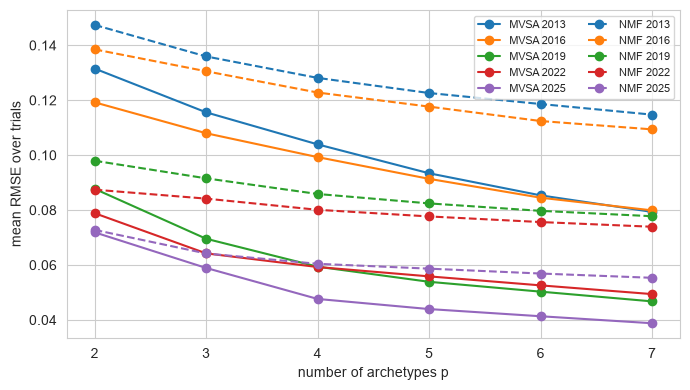

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
ps = [c for c in rmse.columns if c != "HySime k"]
for (label, y), row in rmse.iterrows():
    ax.plot(ps, row[ps], marker="o", ls="-" if label == "MVSA" else "--",
            color=f"C{YEARS.index(y)}", label=f"{label} {y}")
ax.set(xlabel="number of archetypes p", ylabel="mean RMSE over trials")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()

In [15]:
fit = pd.DataFrame(
    {
        "NMF RMSE > MVSA RMSE at every p": (rmse.loc["NMF", ps] > rmse.loc["MVSA", ps]).all(axis=1),
        "MVSA: RMSE(4)/RMSE(6) - 1": rmse.loc["MVSA", 4] / rmse.loc["MVSA", 6] - 1,
        "NMF: RMSE(4)/RMSE(6) - 1": rmse.loc["NMF", 4] / rmse.loc["NMF", 6] - 1,
    }
)
fit.round(3)

,NMF RMSE > MVSA RMSE at every p,MVSA: RMSE(4)/RMSE(6) - 1,NMF: RMSE(4)/RMSE(6) - 1
year,,,
2013,True,0.217,0.080
2016,True,0.175,0.092
2019,True,0.181,0.077
2022,True,0.127,0.059
2025,True,0.152,0.062


## 4. MVSA vs NMF agreement at $p=4$ (outline `tab:agree`)

Hungarian matching of the NMF trial-mean archetypes to the MVSA ones on
top-12 Jaccard. The MVSA column sum is shown because the poorly matched
archetype turns out to be the mostly-negative one (notebook 13).

In [16]:
def short(label):
    return label.split(",")[0].title()


rows = []
for y in YEARS:
    A = SWEEPS[(y, "mvsa")][P_MAIN]["loadings_mean"]
    B = SWEEPS[(y, "nmf")][P_MAIN]["loadings_mean"]
    common = A.index.intersection(B.index)
    if len(common) != len(A) or len(common) != len(B):
        print(f"{y}: candidate sets differ (MVSA {len(A)}, NMF {len(B)}); using {len(common)} shared")
    A, B = A.loc[common], B.loc[common]
    perm, sim = match_to_reference(A.to_numpy(), B.to_numpy(), similarity="top12_jaccard")
    for k, (j, s) in enumerate(zip(perm, sim)):
        rows.append(
            {
                "year": y,
                "MVSA": A.columns[k],
                "NMF": B.columns[j],
                "top-12 Jaccard": s,
                "MVSA top 3": " / ".join(short(c) for c in A.iloc[:, k].nlargest(3).index),
                "NMF top 3": " / ".join(short(c) for c in B.iloc[:, j].nlargest(3).index),
                "MVSA column sum": A.iloc[:, k].sum(),
            }
        )
agree = pd.DataFrame(rows)
agree.round(2)

,year,MVSA,NMF,top-12 Jaccard,MVSA top 3,NMF top 3,MVSA column sum
0,2013,arch_0,arch_0,0.60,Hontiveros / Aquino / Magsaysay,Gordon / Zubiri / Pimentel,24.05
1,2013,arch_1,arch_2,0.71,Poe / Escudero / Legarda,Poe / Escudero / Cayetano,-4.57
2,2013,arch_2,arch_3,1.00,Ejercito Estrada / Honasan / Binay,Binay / Ejercito Estrada / Poe,19.70
3,2013,arch_3,arch_1,0.71,Binay / Zubiri / Enrile,Binay / Zubiri / Aquino,3.17
4,2016,arch_0,arch_2,0.60,Drilon / De Lima / Pangilinan,Drilon / De Lima / Pangilinan,12.76
5,2016,arch_1,arch_3,0.60,Zubiri / Tolentino / Gordon,Gordon / Lacson / Gatchalian,15.69
6,2016,arch_2,arch_0,0.14,Romualdez / Petilla / Lapid,Romualdez / Pacquiao / Petilla,-7.14
7,2016,arch_3,arch_1,0.85,Sotto / Villanueva / Lacson,Sotto / Villanueva / Lacson,23.90
8,2019,arch_0,arch_2,0.85,Dela Rosa / Go / Tolentino,Marcos / Villar / Cayetano,13.23
9,2019,arch_1,arch_0,0.85,Marcos / Bong Revilla / Lapid,Lapid / Villar / Poe,13.50


In [17]:
# Per year: matched Jaccards sorted high to low (outline layout)
agree.groupby("year")["top-12 Jaccard"].apply(
    lambda s: " / ".join(f"{v:.2f}" for v in sorted(s, reverse=True))
)

year
2013    1.00 / 0.71 / 0.71 / 0.60
2016    0.85 / 0.60 / 0.60 / 0.14
2019    0.85 / 0.85 / 0.85 / 0.09
2022    0.85 / 0.85 / 0.60 / 0.26
2025    1.00 / 0.85 / 0.71 / 0.26
Name: top-12 Jaccard, dtype: str

In [18]:
# Is the worst-matched MVSA archetype the one with a negative column sum?
worst = agree.loc[agree.groupby("year")["top-12 Jaccard"].idxmin()]
worst.assign(negative_column_sum=worst["MVSA column sum"] < 0)[
    ["year", "MVSA", "MVSA top 3", "top-12 Jaccard", "MVSA column sum", "negative_column_sum"]
].round(2)

,year,MVSA,MVSA top 3,top-12 Jaccard,MVSA column sum,negative_column_sum
0,2013,arch_0,Hontiveros / Aquino / Magsaysay,0.60,24.05,False
6,2016,arch_2,Romualdez / Petilla / Lapid,0.14,-7.14,True
11,2019,arch_3,Gutoc / Bong Revilla / Roxas,0.09,-8.99,True
15,2022,arch_3,Padilla / Del Rosario / Pimentel,0.26,-4.54,True
18,2025,arch_2,Revillame / Tulfo / Pacquiao,0.26,-9.86,True


## Summary

Numbers from the run above (all five years at min 25th percentile = 10 and
min precinct votes = 10; 2013: 19 candidates, 2016: 32).

- **Provenance:** in every year the MVSA and NMF sweeps share preprocessing
  and match the current config.
- **Distinctness (`jac12`, min pairwise distance):** "d(5) < min d(2..4)" holds
  in 4/5 years for MVSA (not 2016) and 4/5 for NMF (not 2025). The stricter
  "max d(5..7) < min d(2..4)" holds in 3/5 for each (MVSA: 2019, 2022, 2025;
  NMF: 2013, 2016, 2019). Other metrics: `wtau` 4/3, `rbo` 3/4, `spearman` 3/3,
  `cos`/`cos12` at most 2.
- **Stability at $p=4$ (`jac12` means):** NMF less order-sensitive (arm B) in
  4/5 years (not 2016: NMF 0.69 vs MVSA 0.92); NMF more seed-sensitive (arm C)
  in 3/5 (2013, 2022, 2025; not 2016 or 2019).
- **Fit:** NMF RMSE above MVSA at every $p$ in every year. MVSA RMSE at $p=4$:
  0.1039 / 0.0993 / 0.0594 / 0.0593 / 0.0476 (2013 ... 2025). HySime $k$:
  4 / 5 / 5 / 6 / 6.
- **Agreement at $p=4$:** matched `jac12` per year 2013: 1.00/0.71/0.71/0.60;
  2016: 0.85/0.60/0.60/0.14; 2019: 0.85/0.85/0.85/0.09; 2022: 0.85/0.85/0.60/0.26;
  2025: 1.00/0.85/0.71/0.26. The worst-matched MVSA archetype has a negative
  column sum in 4/5 years; in 2013 it is arch_0 (Hontiveros / Aquino /
  Magsaysay, column sum 24.05) and the negative arch_1 matches at 0.71.
